# 18 — Which feature groups carry the information? Ablation of the production features (System I, N3)

The old notebook 18 ablated the training budget, the network and the density-estimator family on the pre-fix simulator. Under the N3 re-run the budget study is notebook 31/36 and the architecture is fixed (NSF 128/5); what is open is **which of the production features matter**.
The production set S1m has 34 features: the 29 base summaries (per-channel statistics, final-window means, aggregates, two physics proxies), three plug-in estimators of ln α and ln β computed with the measured inlet, and the two measured temperatures.

**Design (fixed before running; runbook §2f row g-18).** Same data as notebook 36: its 160k bank, its 20 000-simulation training recipe (the first 20 000 rows of the seed's permutation), its held-out test set (1,000 SBC draws and the scenario grid). Each feature set is trained with **3 seeds** and evaluated as the 3-member **ensemble** (single members are unreliable, notebooks 31/36).
Sets: **A** base 29 only (no inlet information); **B** base 29 + the two measured temperatures; **C** base 29 + the three estimators; **D** S1m (34, production); **E** estimators + measured temperatures only (5); and, from D, **drop one base group**: per-channel statistics (20), final-window means (4), aggregates (3), physics proxies (2).
Reported per set: SBC interior KS p and TARP p, 90% coverage, mean posterior sd of α and β, macro-F1 and accuracy on the scenario grid, β coverage and sd per scenario. **Checks:** finite; set D reproduces the notebook-36 ensemble's β sd within 15% (a different member count). No decision rule: a descriptive ablation.


In [1]:
import os, sys, time, pickle, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
warnings.filterwarnings("ignore")
import importlib, ws_eval, nb36_production_measured_inlet, summary_variants
for _m in (ws_eval, nb36_production_measured_inlet, summary_variants):
    importlib.reload(_m)
we, P36, sv = ws_eval, nb36_production_measured_inlet, summary_variants
from cstr_sbi.summaries import FEATURE_GROUPS, FEATURE_NAMES
R = ROOT / "results"; OUTD = R / "18_N3"; OUTD.mkdir(exist_ok=True); FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True); T0 = time.time()
torch.set_num_threads(4)
BUDGET, SEEDS = 20_000, (0, 1, 2)
th, X = P36.load_bank(); test = we.load_npz(P36.OUT / "test.npz")
assert X.shape[1] == 34 and np.isfinite(X).all()
BASE = list(sv.BASE29); NAMES = BASE + list(sv.EST) + ["Ti_meas", "Tci_meas"]
ix = lambda sel: [NAMES.index(n) for n in sel]
g = lambda name: [BASE[i] for i in range(29) if BASE[i] in FEATURE_GROUPS[name]]
def drop(group): return [n for n in NAMES if n not in g(group)]
SETS = {"A base 29 (no inlet information)": BASE, "B base 29 + measured temperatures": BASE + ["Ti_meas", "Tci_meas"], "C base 29 + 3 estimators": BASE + list(sv.EST),
        "D S1m (34, production)": NAMES, "E estimators + measured temperatures (5)": list(sv.EST) + ["Ti_meas", "Tci_meas"],
        "D minus per-channel statistics": drop("per_channel"), "D minus final-window means": drop("final_window"), "D minus aggregates": drop("aggregates"), "D minus physics proxies": drop("physics")}
for k, v in SETS.items(): print(f"{k}: {len(v)} features")


A base 29 (no inlet information): 29 features
B base 29 + measured temperatures: 31 features
C base 29 + 3 estimators: 32 features
D S1m (34, production): 34 features
E estimators + measured temperatures (5): 5 features
D minus per-channel statistics: 14 features
D minus final-window means: 30 features
D minus aggregates: 31 features
D minus physics proxies: 32 features


## 1. Train (3 seeds per set, 20,000 simulations; cached) and evaluate the 3-member ensembles

In [2]:
def path(si, s): return OUTD / f"post_set{si}_s{s}.pkl"
rows, sc_rows = [], []
for si, (name, sel) in enumerate(SETS.items()):
    cols = np.array(ix(sel)); members = []
    for s in SEEDS:
        f = path(si, s)
        if not f.exists():
            perm = np.random.default_rng(36_000 + s).permutation(len(th)); idx = perm[:BUDGET]
            post, meta = we.train_npe(th[idx], X[idx][:, cols], seed=s)
            pickle.dump({"posterior": post, "metadata": meta}, open(f, "wb"))
        members.append(pickle.load(open(f, "rb"))["posterior"])
    tsub = dict(test); tsub["x_sbc"] = test["x_sbc"][:, cols]; tsub["x_sc"] = test["x_sc"][:, cols]
    row, scr = we.evaluate(we.EnsemblePosterior(members), tsub, seed=0)
    rows.append(dict(set=name, n_features=len(cols), **{k: row[k] for k in ("ks_p_a_interior", "ks_p_b_interior", "tarp_ks_p", "cov90_a", "cov90_b", "sd_a", "sd_b", "rmse_norm", "macro_f1", "accuracy", "leak_sbc_mean")}))
    sc_rows += [dict(set=name, **r) for r in scr]
    print(f"{name}: done {time.time() - T0:.0f}s", flush=True)
abl = pd.DataFrame(rows); display(abl.round(3)); abl.to_csv(R / "18_N3_ablation.csv", index=False)
pd.DataFrame(sc_rows).to_csv(R / "18_N3_ablation_scenarios.csv", index=False)


A base 29 (no inlet information): done 268s


B base 29 + measured temperatures: done 462s


C base 29 + 3 estimators: done 654s


D S1m (34, production): done 849s


E estimators + measured temperatures (5): done 1036s


D minus per-channel statistics: done 1278s


D minus final-window means: done 1439s


D minus aggregates: done 1635s


D minus physics proxies: done 1837s


,set,n_features,ks_p_a_interior,ks_p_b_interior,tarp_ks_p,cov90_a,cov90_b,sd_a,sd_b,rmse_norm,macro_f1,accuracy,leak_sbc_mean
0,A base 29 (no inlet information),29,0.410,0.027,0.168,0.911,0.896,0.037,0.126,0.127,0.650,0.660,0.011
1,B base 29 + measured temperatures,31,0.077,0.337,0.500,0.916,0.905,0.037,0.043,0.049,0.823,0.823,0.013
2,C base 29 + 3 estimators,32,0.002,0.405,0.252,0.916,0.902,0.037,0.043,0.049,0.842,0.830,0.013
3,"D S1m (34, production)",34,0.020,0.178,0.896,0.912,0.900,0.036,0.042,0.049,0.813,0.803,0.013
4,E estimators + measured temperatures (5),5,0.569,0.172,0.710,0.911,0.913,0.035,0.053,0.056,0.735,0.730,0.013
5,D minus per-channel statistics,14,0.039,0.154,0.193,0.912,0.912,0.036,0.048,0.052,0.764,0.753,0.010
6,D minus final-window means,30,0.037,0.464,0.811,0.902,0.898,0.035,0.042,0.049,0.806,0.797,0.018
7,D minus aggregates,31,0.458,0.121,0.657,0.909,0.894,0.036,0.042,0.049,0.812,0.800,0.014
8,D minus physics proxies,32,0.280,0.176,0.252,0.913,0.905,0.036,0.042,0.049,0.813,0.800,0.013


## 2. Check against notebook 36 and per-scenario β

set D (3-member ensemble): sd_b 0.0425, sd_a 0.0358 | notebook 36 (5-member ensemble): sd_b 0.0426, sd_a 0.0364
check passed: set D reproduces the notebook-36 beta sd within 15%


sc,Sc1,Sc2,Sc3,Sc4,Sc5,Sc7
set,,,,,,
A base 29 (no inlet information),0.131,0.137,0.125,0.136,0.123,0.037
B base 29 + measured temperatures,0.044,0.044,0.045,0.044,0.043,0.044
C base 29 + 3 estimators,0.043,0.043,0.043,0.043,0.043,0.029
"D S1m (34, production)",0.044,0.044,0.044,0.044,0.043,0.029
D minus aggregates,0.043,0.042,0.042,0.042,0.043,0.029
D minus final-window means,0.043,0.043,0.044,0.043,0.043,0.032
D minus per-channel statistics,0.050,0.050,0.052,0.051,0.045,0.021
D minus physics proxies,0.043,0.043,0.043,0.042,0.044,0.038
E estimators + measured temperatures (5),0.057,0.057,0.060,0.059,0.046,0.024


sc,Sc1,Sc2,Sc3,Sc4,Sc5,Sc7
set,,,,,,
A base 29 (no inlet information),0.92,0.90,0.96,0.90,0.98,0.0
B base 29 + measured temperatures,0.88,0.86,0.92,0.94,0.92,0.0
C base 29 + 3 estimators,0.88,0.88,0.88,0.94,0.94,0.0
"D S1m (34, production)",0.88,0.88,0.94,0.94,0.92,0.0
D minus aggregates,0.88,0.88,0.92,0.94,0.90,0.0
D minus final-window means,0.90,0.88,0.90,0.92,0.94,0.0
D minus per-channel statistics,0.90,0.88,0.88,0.94,0.92,0.0
D minus physics proxies,0.90,0.86,0.94,0.94,0.94,0.0
E estimators + measured temperatures (5),0.86,0.84,0.84,0.92,0.92,0.0


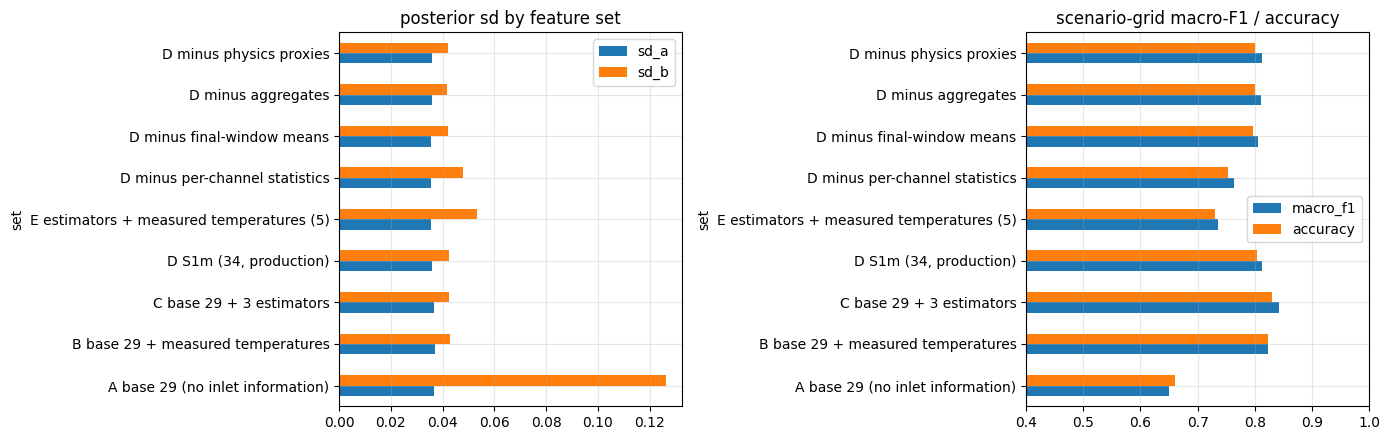

notebook wall time 30.7 min


In [3]:
m36 = pd.read_csv(R / "36_N3_metrics.csv"); ref = m36[(m36.budget == 20000) & (m36.member == "ensemble")].iloc[0]
d_row = abl[abl.set == "D S1m (34, production)"].iloc[0]
print(f"set D (3-member ensemble): sd_b {d_row.sd_b:.4f}, sd_a {d_row.sd_a:.4f} | notebook 36 (5-member ensemble): sd_b {ref.sd_b:.4f}, sd_a {ref.sd_a:.4f}")
assert abs(d_row.sd_b / ref.sd_b - 1) < 0.15, "reproduction check failed"
print("check passed: set D reproduces the notebook-36 beta sd within 15%")
sc = pd.DataFrame(sc_rows); sc["sc"] = sc.scenario.str.split("_").str[0]
display(sc.pivot_table(index="set", columns="sc", values="sd_b").round(3)); display(sc.pivot_table(index="set", columns="sc", values="cov90_truth_b").round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5)); a = abl.set_index("set")
a[["sd_a", "sd_b"]].plot.barh(ax=ax[0]); ax[0].set_title("posterior sd by feature set"); a[["macro_f1", "accuracy"]].plot.barh(ax=ax[1]); ax[1].set_title("scenario-grid macro-F1 / accuracy"); ax[1].set_xlim(0.4, 1.0)
for a_ in ax: a_.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIGS / "18_N3_feature_ablation.png", dpi=150); plt.show()
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


## 6. Interpretation

All sets: 20,000 simulations, 3-member ensembles, notebook 36's test set. Set D (the production features) reproduces notebook 36's β sd (0.0425 against 0.0426) and α sd (0.0358 against 0.0364), so the ablation is on the right scale.

**The inlet information is what matters.** Without any information on the inlet (**A**, the 29 base summaries) the β posterior is three times wider (sd 0.126 against 0.042–0.043; α unchanged at 0.037) and the scenario-grid macro-F1 falls from 0.81–0.84 to 0.65. This is the same number as the unmeasured-inlet failure of notebook 34, seen from the feature side: the base summaries cannot separate a ±2 K inlet from fouling.
Adding the two **measured temperatures** (B) recovers essentially all of it (β sd 0.043, macro-F1 0.823); adding the three plug-in **estimators** (C), which embed the measured temperatures, does the same (β sd 0.043, macro-F1 0.842). Either route is enough, and the network can recompute the estimators from the base summaries plus the measured temperatures (B ≈ C ≈ D). **The estimators are a convenience, not a necessity; the measured temperatures are the necessity.**

**Five features carry most of it.** The three estimators plus the two measured temperatures alone (E) give β sd 0.046–0.060 (0.053 on average), within about 25% of the full set, and macro-F1 0.735. They are not enough to match the full set in classification, which means that the remaining information sits in the per-channel statistics.

**Which base groups matter.** Dropping the per-channel statistics (D minus per-channel, 14 features left) is the only drop that costs anything: β sd rises to 0.048 on average (0.050–0.052 in Sc1–Sc4), macro-F1 falls from 0.81 to 0.76. Dropping the final-window means, the three aggregates or the two physics proxies changes nothing outside the noise (β sd 0.042–0.043, macro-F1 0.806–0.813): these are redundant given the rest.
The old M3 conclusion that a compact feature vector suffices therefore holds for S1m: the 20 per-channel statistics plus the five inlet-aware features carry the information, and each of the three redundant groups (4, 3 and 2 features) can be dropped without a visible loss (dropped one at a time; jointly untested); notebook 03 section 10 already found that no candidate feature adds information beyond the base set under a nominal inlet.

**Calibration and the scenario grid.** Coverage is 0.89–0.92 in every set. The interior-SBC KS p-values of 3-member ensembles are noisy (set C α 0.002, set D α 0.020, the 5-member production ensemble 0.063); the production comparison is by width and coverage, not by these p-values. The accuracy differences between B, C and D (0.80–0.83) are within the sampling noise of the scenario grid. Sc7 coverage is 0.00 in every set: **no feature subset repairs the sensor-drift misspecification**
(that needs the drift parameter, notebook 09).

**Ledger.** Supports: the measured inlet temperatures as the necessary new information (A → B: ×3 in the β sd); the redundancy of the estimators, final-window means, aggregates and physics proxies; the per-channel statistics as the group to keep. Documents: the 3-member ensemble's noisy SBC. Does not support: any claim about budget, network width/depth or density-estimator family (the old notebook 18; not re-run, the budget study is notebooks 31 and 36).